<a href="https://colab.research.google.com/github/VeenaDalavi24/Diabetes-Prediction-ML/blob/main/Diabetes_task1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

LOAD DATASET

In [ ]:
df = pd.read_csv("/content/diabetes.csv")

print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


CHECK DATASET

In [ ]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

DATA CLEANING

In [ ]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in cols:
    df[col] = df[col].replace(0, df[col].median())

EDA

OUTCOME COUNT

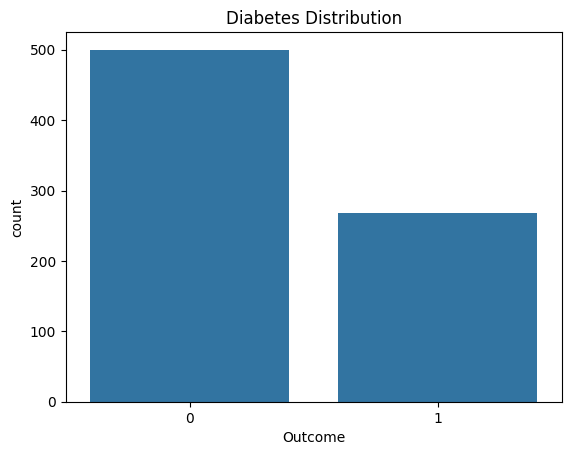

In [ ]:
sns.countplot(x='Outcome', data=df)
plt.title("Diabetes Distribution")
plt.show()

CORRELATION HEATMAP

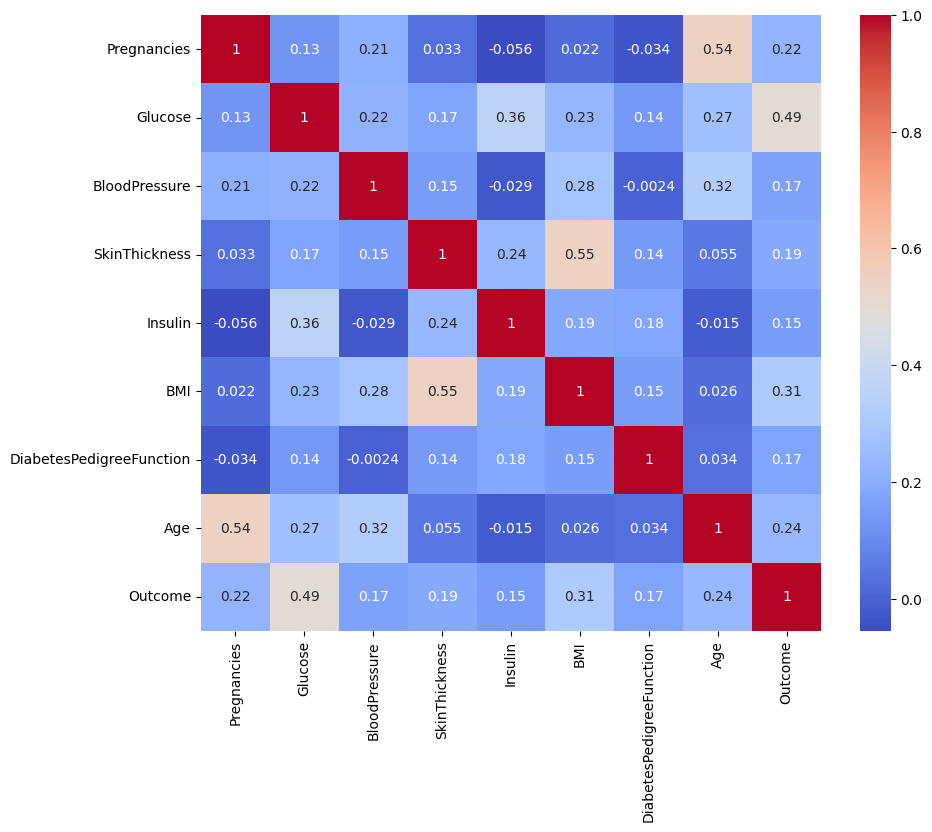

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()


AGE

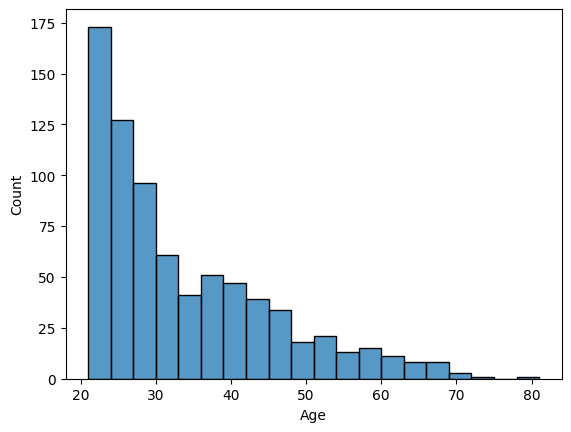

In [ ]:
sns.histplot(df['Age'], bins=20)
plt.show()

BMI DISTRIBUTION

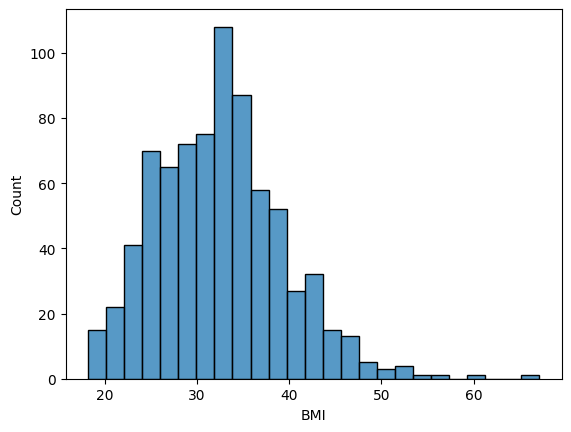

In [ ]:
sns.histplot(df['BMI'])
plt.show()

GLUCOSE DISTRIBUTION


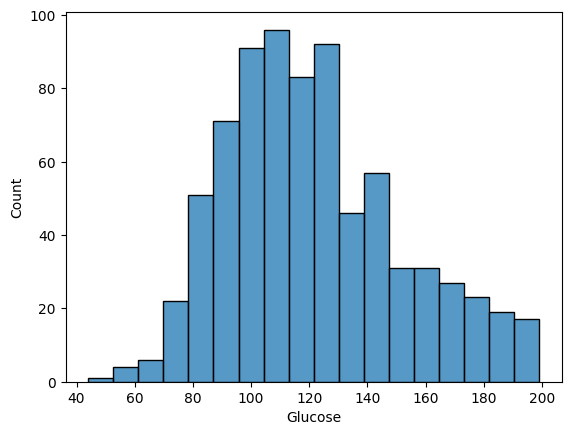

In [ ]:
sns.histplot(df['Glucose'])
plt.show()

SPLIT DATASET

In [ ]:
X = df.drop('Outcome', axis=1)

y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

TRAIN MODEL

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

PREDICTION


In [ ]:
prediction = model.predict(X_test)

ACCURACY SCORE


In [ ]:
accuracy = accuracy_score(y_test, prediction)

print("Accuracy:", accuracy)

Accuracy: 0.7597402597402597


CLASSIFICATION REPORT

In [ ]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       0.80      0.83      0.82        99
           1       0.67      0.64      0.65        55

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.74       154
weighted avg       0.76      0.76      0.76       154



CONFUSION MATRIX

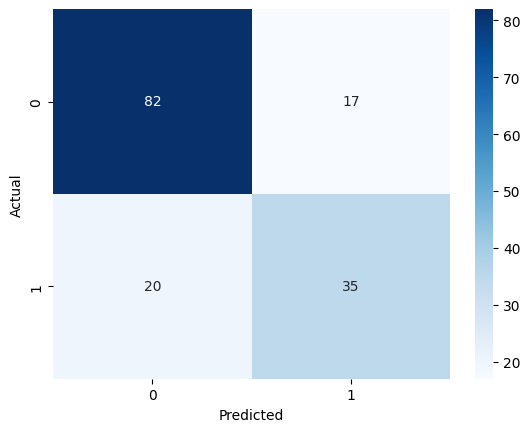

In [ ]:
cm = confusion_matrix(y_test, prediction)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

PREDICTION OF PATIENT

In [ ]:
patient=[[3,158,76,36,245,31.6,0.851,28]]
patient_as_numpy_array = np.asarray(patient)
patient_reshaped = patient_as_numpy_array.reshape(1,-1)

result=model.predict(patient)
print(result)

if result[0]==1:
    print("Patient is likely to have Diabetes")
else:
    print("Patient is unlikely to have Diabetes")

[1]
Patient is likely to have Diabetes


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
